# Notebook 01 – Khảo sát dữ liệu (EDA) và đánh giá chất lượng dữ liệu
Bài toán: hồi quy dự đoán `mpg` từ thông số kỹ thuật của xe (Auto MPG, 398 mẫu).
Notebook chạy từ đầu đến cuối, dùng đường dẫn tương đối (chạy từ thư mục `notebooks/`), không huấn luyện mô hình.
Mỗi biểu đồ có một ô nhận xét ngay sau đó.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from pathlib import Path

SEED = 42
DATA = Path("../data/raw/auto-mpg.csv")
FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

LABEL = {"mpg": "MPG (dặm/gallon)", "cylinders": "Số xi-lanh", "displacement": "Dung tích xi-lanh (inch khối)",
         "horsepower": "Công suất (mã lực)", "weight": "Khối lượng (lb)",
         "acceleration": "Thời gian tăng tốc 0–60 mph (giây)", "model_year": "Năm sản xuất (19xx)"}
NUM = list(LABEL)
df = pd.read_csv(DATA)
print(df.shape)
df.head()

(398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


## 1. Thống kê mô tả

In [2]:
desc = df[NUM].describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
desc["skew"] = df[NUM].skew()
print(df.dtypes.to_string(), "\n")
desc.round(2)

mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight            int64
acceleration    float64
model_year        int64
origin              str
name                str 



,count,mean,std,min,25%,50%,75%,max,skew
mpg,398.0,23.51,7.82,9.0,17.50,23.0,29.00,46.6,0.46
cylinders,398.0,5.45,1.70,3.0,4.00,4.0,8.00,8.0,0.53
displacement,398.0,193.43,104.27,68.0,104.25,148.5,262.00,455.0,0.72
horsepower,392.0,104.47,38.49,46.0,75.00,93.5,126.00,230.0,1.09
weight,398.0,2970.42,846.84,1613.0,2223.75,2803.5,3608.00,5140.0,0.53
acceleration,398.0,15.57,2.76,8.0,13.82,15.5,17.18,24.8,0.28
model_year,398.0,76.01,3.70,70.0,73.00,76.0,79.00,82.0,0.01


**Nhận xét.** MPG trung bình 23,51, độ lệch chuẩn 7,82, nằm trong khoảng 9,0–46,6; trung vị (23,0) gần trung bình nên phân phối khá cân đối, chỉ lệch phải nhẹ (skew 0,46). `horsepower` lệch phải rõ nhất (skew 1,09; trung bình 104,47 lớn hơn trung vị 93,5) và `displacement` cũng lệch phải (skew 0,72). Các đặc trưng có thang đo rất khác nhau (`weight` cỡ hàng nghìn, `acceleration` cỡ hàng chục), nên cần chuẩn hóa trước khi dùng Ridge hoặc KNN. Chỉ `horsepower` có `count` = 392 (thiếu 6 giá trị).

## 2. Phân bố biến mục tiêu và các đặc trưng

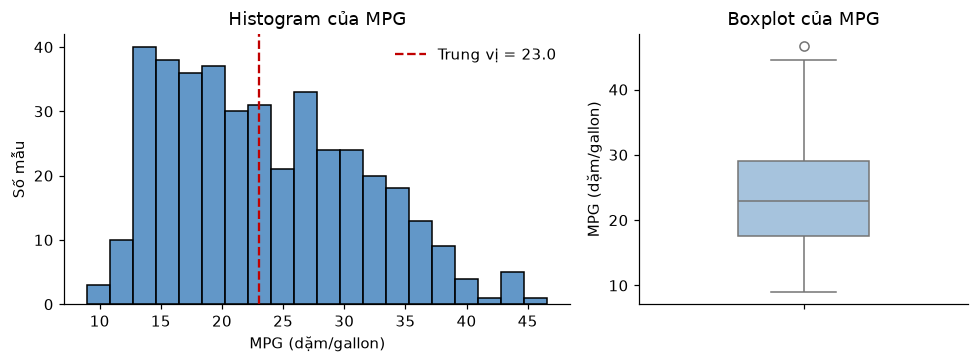

Q1, Q3 = 17.5 29.0 | hàng rào IQR trên = 46.25
      mpg       name  model_year
322  46.6  mazda glc          80


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4), gridspec_kw={"width_ratios": [2, 1.3]})
sns.histplot(df["mpg"], bins=20, color="#2E75B6", ax=ax[0])
ax[0].axvline(df["mpg"].median(), color="#C00000", ls="--", label=f"Trung vị = {df['mpg'].median():.1f}")
ax[0].set(xlabel=LABEL["mpg"], ylabel="Số mẫu", title="Histogram của MPG"); ax[0].legend(frameon=False)
sns.boxplot(y=df["mpg"], color="#9DC3E6", ax=ax[1], width=0.4)
ax[1].set(ylabel=LABEL["mpg"], title="Boxplot của MPG")
plt.tight_layout(); plt.savefig(FIG / "hinh_2_1_phan_bo_mpg.png", dpi=150); plt.show()
q1, q3 = df["mpg"].quantile([.25, .75]); print("Q1, Q3 =", q1, q3, "| hàng rào IQR trên =", q3 + 1.5 * (q3 - q1))
print(df.loc[df["mpg"] > q3 + 1.5 * (q3 - q1), ["mpg", "name", "model_year"]])

**Nhận xét.** Một nửa số xe có MPG trong khoảng 17,5–29,0; phân phối một đỉnh, đuôi kéo dài sang phải (xe tiết kiệm trên 40 dặm/gallon rất ít). Boxplot chỉ đánh dấu 1 giá trị ngoại lai là `mazda glc` (46,6), đây là xe nhỏ thật, không phải lỗi nhập liệu. MPG là biến liên tục nên không có vấn đề mất cân bằng lớp, nhưng vùng MPG cao có ít mẫu nên mô hình có thể kém tin cậy hơn ở vùng này.

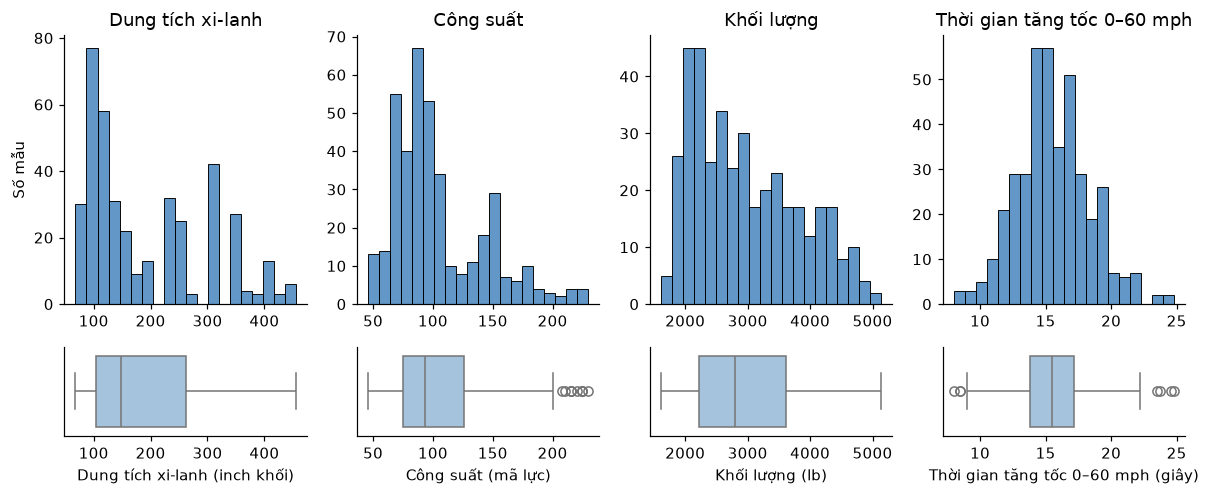

displacement  skew=0.72  Q1-Q3=(104.2, 262.0)  ngoại lai IQR: 0
horsepower    skew=1.09  Q1-Q3=(75.0, 126.0)  ngoại lai IQR: 10
weight        skew=0.53  Q1-Q3=(2223.8, 3608.0)  ngoại lai IQR: 0
acceleration  skew=0.28  Q1-Q3=(13.8, 17.2)  ngoại lai IQR: 7


In [4]:
feats = ["displacement", "horsepower", "weight", "acceleration"]
fig, ax = plt.subplots(2, 4, figsize=(11, 4.6), gridspec_kw={"height_ratios": [3, 1]})
for j, c in enumerate(feats):
    sns.histplot(df[c], bins=20, color="#2E75B6", ax=ax[0, j]); ax[0, j].set(xlabel="", ylabel="Số mẫu" if j == 0 else "", title=LABEL[c].split(" (")[0])
    sns.boxplot(x=df[c], color="#9DC3E6", ax=ax[1, j]); ax[1, j].set(xlabel=LABEL[c], yticks=[])
plt.tight_layout(); plt.savefig(FIG / "hinh_2_2_phan_bo_dac_trung.png", dpi=150); plt.show()
for c in feats:
    q1, q3 = df[c].quantile([.25, .75]); lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    print(f"{c:13s} skew={df[c].skew():.2f}  Q1-Q3=({q1:.1f}, {q3:.1f})  ngoại lai IQR: {((df[c] < lo) | (df[c] > hi)).sum()}")

**Nhận xét theo từng biểu đồ.**
- *displacement*: lệch phải (skew 0,72), một nửa số xe có dung tích 104–262 inch khối, đuôi kéo tới 455: phần lớn là xe nhỏ, một nhóm ít hơn là xe động cơ lớn. Không có ngoại lai theo IQR.
- *horsepower*: lệch phải mạnh nhất (skew 1,09), Q1–Q3 là 75–126 mã lực; 10 điểm vượt hàng rào IQR (trên 202,5 mã lực). Đó là các xe Mỹ cỡ lớn (chevrolet impala, pontiac grand prix, buick electra 225…), là giá trị thật.
- *weight*: skew 0,53, khoảng 1613–5140 lb, không có ngoại lai IQR; phân phối trải rộng nên là đặc trưng có độ phân tách tốt.
- *acceleration*: gần đối xứng (skew 0,28), trung bình 15,57 giây; 7 điểm ngoại lai ở hai phía: nhanh (8,0–8,5 giây, như plymouth 'cuda 340) và chậm (23,5–24,8 giây, như peugeot 504, xe VW diesel). Đây cũng là các xe có thật.

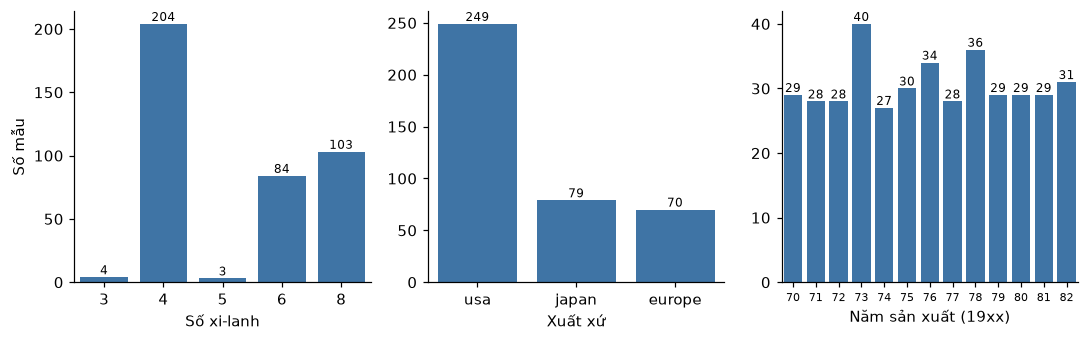

{4: 51.3, 8: 25.9, 6: 21.1, 3: 1.0, 5: 0.8}
{'usa': 62.6, 'japan': 19.8, 'europe': 17.6}
{'min': 27, 'max': 40}


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(10, 3.2))
for a, c in zip(ax, ["cylinders", "origin", "model_year"]):
    order = df[c].value_counts().index if c == "origin" else sorted(df[c].unique())
    sns.countplot(x=df[c], order=order, color="#2E75B6", ax=a)
    for p in a.patches: a.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=8)
    a.set(xlabel=LABEL.get(c, "Xuất xứ"), ylabel="Số mẫu" if c == "cylinders" else "")
ax[2].tick_params(axis="x", labelsize=7)
plt.tight_layout(); plt.savefig(FIG / "hinh_2_3_phan_bo_nhom.png", dpi=150); plt.show()
print((df["cylinders"].value_counts(normalize=True) * 100).round(1).to_dict())
print((df["origin"].value_counts(normalize=True) * 100).round(1).to_dict())
print(df["model_year"].value_counts().agg(["min", "max"]).to_dict())

**Nhận xét theo từng biểu đồ.**
- *cylinders*: mất cân bằng rõ. Xe 4 xi-lanh chiếm 204 mẫu (51,3%), 8 xi-lanh 103 mẫu (25,9%), 6 xi-lanh 84 mẫu (21,1%); loại 3 và 5 xi-lanh chỉ có 4 và 3 mẫu (1,8%), quá ít để học riêng và có thể không xuất hiện ở tập kiểm tra.
- *origin*: xe Mỹ chiếm 249 mẫu (62,6%), Nhật 79 mẫu (19,8%), châu Âu 70 mẫu (17,6%): lệch về xe Mỹ, nên khi chia tập cần kiểm tra tỷ lệ xuất xứ ở hai tập.
- *model_year*: mỗi năm có 27–40 mẫu trải khá đều qua 13 năm 1970–1982, nên không có năm nào chi phối dữ liệu.

## 3. Quan hệ giữa các đặc trưng và với MPG

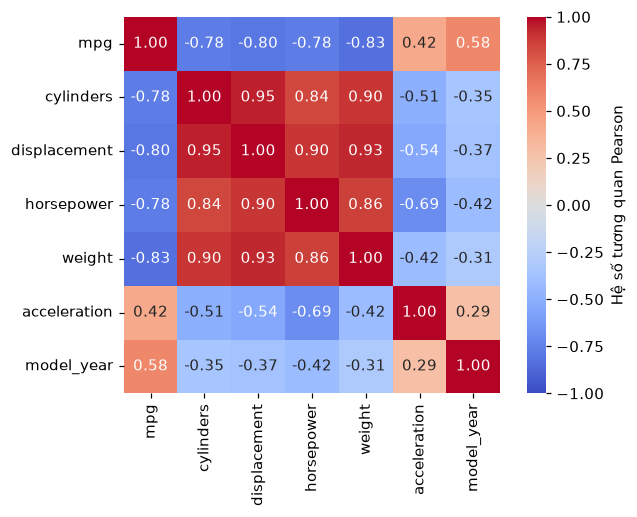

{'cylinders': -0.775, 'displacement': -0.804, 'horsepower': -0.778, 'weight': -0.832, 'acceleration': 0.42, 'model_year': 0.579}
VIF: {'cylinders': 10.6, 'displacement': 19.7, 'horsepower': 9.0, 'weight': 10.5, 'acceleration': 2.6, 'model_year': 1.2}
corr(log weight, log mpg) = -0.874 | corr(weight, mpg) = -0.832


In [6]:
corr = df[NUM].corr()
fig, ax = plt.subplots(figsize=(6.2, 4.8))
short = {"mpg": "mpg", "cylinders": "cylinders", "displacement": "displacement", "horsepower": "horsepower", "weight": "weight", "acceleration": "acceleration", "model_year": "model_year"}
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, cbar_kws={"label": "Hệ số tương quan Pearson"}, ax=ax)
plt.tight_layout(); plt.savefig(FIG / "hinh_2_4_ma_tran_tuong_quan.png", dpi=150); plt.show()
print(corr["mpg"].drop("mpg").round(3).to_dict())

# VIF = 1 / (1 - R^2) khi hồi quy từng đặc trưng theo các đặc trưng còn lại (điền thiếu bằng trung vị chỉ để tính VIF)
X = df[NUM[1:]].fillna(df[NUM[1:]].median())
vif = {c: 1 / (1 - LinearRegression().fit(X.drop(columns=c), X[c]).score(X.drop(columns=c), X[c])) for c in X}
print("VIF:", {k: round(v, 1) for k, v in vif.items()})
print("corr(log weight, log mpg) =", round(np.corrcoef(np.log(df.weight), np.log(df.mpg))[0, 1], 3),
      "| corr(weight, mpg) =", round(np.corrcoef(df.weight, df.mpg)[0, 1], 3))

**Nhận xét theo ma trận tương quan (các nhận xét dùng cho xây dựng mô hình).**
1. `weight` (−0,83), `displacement` (−0,80), `horsepower` (−0,78) và `cylinders` (−0,78) tương quan âm mạnh với MPG: xe nặng, động cơ lớn thì tốn nhiên liệu hơn. `model_year` (+0,58) và `acceleration` (+0,42) tương quan yếu hơn.
2. Các đặc trưng này tương quan rất mạnh với nhau: `displacement`–`cylinders` 0,95, `displacement`–`weight` 0,93, `displacement`–`horsepower` 0,90. VIF của `displacement` là 19,7, của `cylinders` 10,6, `weight` 10,5, `horsepower` 9,0 (vượt ngưỡng thường dùng là 5–10) nên có đa cộng tuyến nặng. Hệ số của hồi quy tuyến tính sẽ không ổn định, và mở rộng đa thức làm tình trạng này tệ hơn. Điều này ủng hộ việc dùng Ridge và chọn một tập đặc trưng gọn (khoảng 4 đặc trưng) thay vì dùng hết.
3. `model_year` hầu như độc lập với các đặc trưng còn lại (VIF 1,2) mà vẫn tương quan +0,58 với MPG, nên mang thông tin bổ sung và cần giữ lại.
4. Quan hệ không hoàn toàn tuyến tính: tương quan giữa log(weight) và log(mpg) là −0,874, mạnh hơn dạng tuyến tính (−0,832). Điều này gợi ý mô hình tuyến tính sẽ underfit và đa thức bậc thấp (hoặc biến đổi log) là hợp lý.

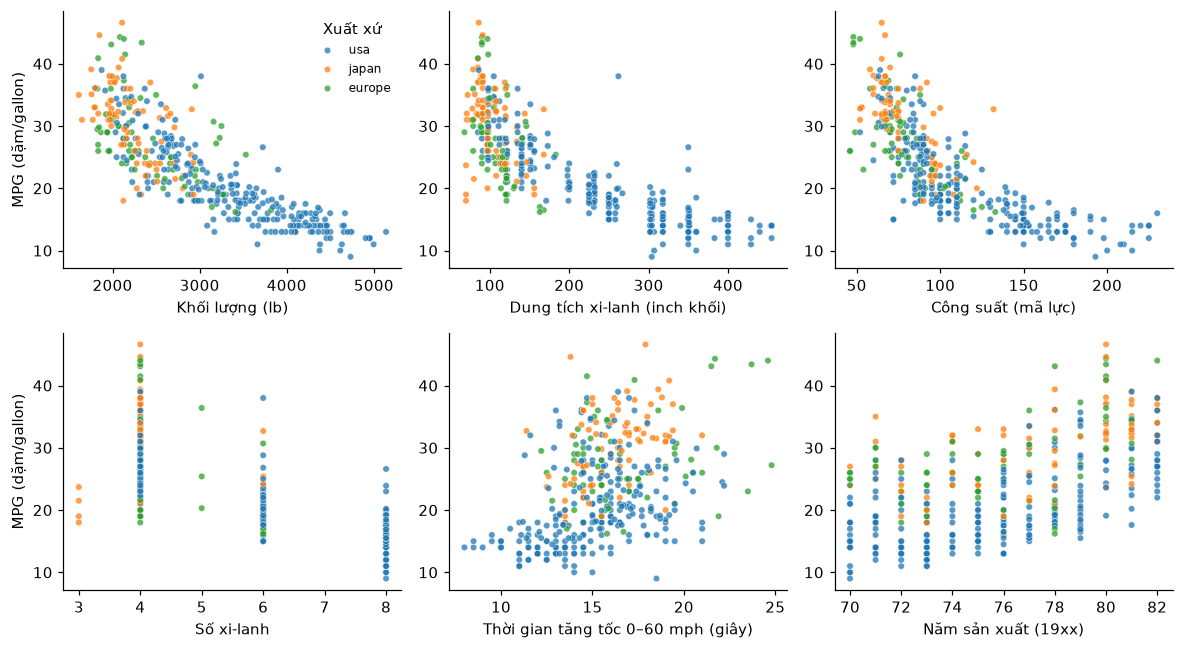

{70: 17.7, 71: 21.2, 72: 18.7, 73: 17.1, 74: 22.7, 75: 20.3, 76: 21.6, 77: 23.4, 78: 24.1, 79: 25.1, 80: 33.7, 81: 30.3, 82: 31.7}


In [7]:
fig, ax = plt.subplots(2, 3, figsize=(11, 6))
for a, c in zip(ax.ravel(), ["weight", "displacement", "horsepower", "cylinders", "acceleration", "model_year"]):
    sns.scatterplot(data=df, x=c, y="mpg", hue="origin", s=18, alpha=0.75, ax=a, legend=(c == "weight"))
    a.set(xlabel=LABEL[c], ylabel=LABEL["mpg"] if c in ("weight", "cylinders") else "")
ax[0, 0].legend(title="Xuất xứ", frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "hinh_2_5_phan_tan_voi_mpg.png", dpi=150); plt.show()
print(df.groupby("model_year")["mpg"].mean().round(1).to_dict())

**Nhận xét theo từng biểu đồ.**
- *weight, displacement, horsepower*: đám mây điểm đi xuống và cong (giảm nhanh ở khoảng khối lượng/công suất thấp rồi chậm dần), chứ không nằm trên một đường thẳng; xe Mỹ tập trung ở vùng nặng, công suất lớn, xe Nhật và châu Âu ở vùng nhẹ, MPG cao.
- *cylinders*: MPG giảm theo số xi-lanh; các nhóm 4, 6, 8 xi-lanh khá tách nhau, còn 3 và 5 xi-lanh chỉ là vài điểm lẻ.
- *acceleration*: quan hệ dương yếu và rất nhiễu (điểm phân tán rộng), nên đặc trưng này ít có giá trị dự đoán một mình.
- *model_year*: xu hướng tăng; MPG trung bình tăng từ 17,7 (1970) lên 31,7 (1982), với bước nhảy lớn từ 25,1 (1979) lên 33,7 (1980).

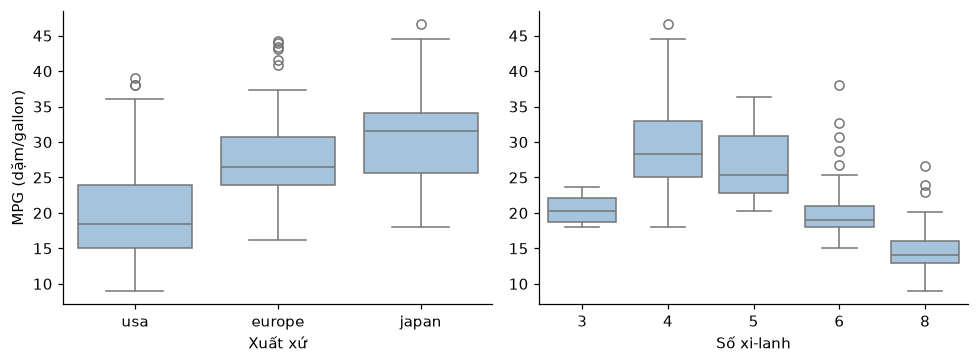

        count   mean
origin              
europe     70  27.89
japan      79  30.45
usa       249  20.08
           count   mean
cylinders              
3              4  20.55
4            204  29.29
5              3  27.37
6             84  19.99
8            103  14.96
        weight  displacement  horsepower
origin                                  
europe  2423.0         109.0        81.0
japan   2221.0         103.0        80.0
usa     3362.0         246.0       119.0


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
sns.boxplot(data=df, x="origin", y="mpg", order=["usa", "europe", "japan"], color="#9DC3E6", ax=ax[0]); ax[0].set(xlabel="Xuất xứ", ylabel=LABEL["mpg"])
sns.boxplot(data=df, x="cylinders", y="mpg", color="#9DC3E6", ax=ax[1]); ax[1].set(xlabel=LABEL["cylinders"], ylabel="")
plt.tight_layout(); plt.savefig(FIG / "hinh_2_6_mpg_theo_nhom.png", dpi=150); plt.show()
print(df.groupby("origin")["mpg"].agg(["count", "mean"]).round(2)); print(df.groupby("cylinders")["mpg"].agg(["count", "mean"]).round(2))
print(df.groupby("origin")[["weight", "displacement", "horsepower"]].mean().round(0))

**Nhận xét.** MPG trung bình của xe Mỹ là 20,08, thấp hơn xe châu Âu (27,89) và Nhật (30,45). Tuy vậy xe Mỹ cũng nặng hơn nhiều (khối lượng trung bình 3362 lb so với 2221 lb của xe Nhật và 2423 lb của xe châu Âu), nên chênh lệch MPG theo xuất xứ có thể chủ yếu do cỡ xe; sẽ kiểm tra khi đưa `origin` vào mô hình cùng `weight`. Theo số xi-lanh, MPG trung bình là 29,29 (4 xi-lanh), 19,99 (6) và 14,96 (8).

## 4. Phát hiện vấn đề chất lượng dữ liệu

In [9]:
rows = []
miss = df.isna().sum(); miss = miss[miss > 0]
rows.append(["Giá trị thiếu", "isna()", "; ".join(f"{k}: {v}/{len(df)} ({v/len(df)*100:.1f}%)" for k, v in miss.items()) + " – các cột khác không thiếu"])
rows.append(["Bản ghi trùng", "duplicated()", f"{df.duplicated().sum()} dòng trùng hoàn toàn; {df.drop(columns='name').duplicated().sum()} dòng trùng khi bỏ cột name; {df['name'].duplicated().sum()} dòng lặp lại tên xe (khác năm/cấu hình)"])
out = []
for c in NUM:
    q1, q3 = df[c].quantile([.25, .75]); lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    n = int(((df[c] < lo) | (df[c] > hi)).sum())
    if n: out.append(f"{c}: {n}")
rows.append(["Ngoại lai (IQR × 1,5)", "Q1 − 1,5·IQR, Q3 + 1,5·IQR", "; ".join(out) + " – các cột còn lại: 0"])
fmt = f"cột số đúng kiểu số: {all(pd.api.types.is_numeric_dtype(df[c]) for c in NUM)}; mpg ≤ 0: {(df.mpg <= 0).sum()}; weight ≤ 0: {(df.weight <= 0).sum()}; name có khoảng trắng thừa: {(df.name != df.name.str.strip()).sum()}"
rows.append(["Sai định dạng", "kiểu dữ liệu, miền giá trị", fmt])
rows.append(["Mất cân bằng nhóm", "value_counts()", "origin: " + ", ".join(f"{k} {v/len(df)*100:.1f}%" for k, v in df.origin.value_counts().items()) + "; cylinders 3 và 5 chỉ có " + str(int(df.cylinders.isin([3, 5]).sum())) + " mẫu; mpg là biến liên tục (không có lớp nhãn)"])
rows.append(["Lệch phân phối / khác thang đo", "skew(), describe()", f"horsepower skew {df.horsepower.skew():.2f}; displacement {df.displacement.skew():.2f}; weight ~10³ so với acceleration ~10¹"])
rows.append(["Đa cộng tuyến", "VIF", ", ".join(f"{k} {v:.1f}" for k, v in vif.items() if v > 5) + " (> 5)"])
rows.append(["Nguy cơ rò rỉ dữ liệu", "xem xét quy trình", "(1) điền thiếu/chuẩn hóa/sinh đa thức trên toàn bộ dữ liệu trước khi chia; (2) cột name: 93 tên lặp có thể nằm ở cả hai tập; (3) model_year có thứ tự thời gian, chia ngẫu nhiên cho phép 'nhìn thấy' các năm sau"])
quality = pd.DataFrame(rows, columns=["Vấn đề", "Cách kiểm tra", "Kết quả định lượng"])
quality.to_csv("../reports/bang_van_de_chat_luong_du_lieu.csv", index=False, encoding="utf-8-sig")
pd.set_option("display.max_colwidth", 200); quality

,Vấn đề,Cách kiểm tra,Kết quả định lượng
0,Giá trị thiếu,isna(),horsepower: 6/398 (1.5%) – các cột khác không thiếu
1,Bản ghi trùng,duplicated(),0 dòng trùng hoàn toàn; 0 dòng trùng khi bỏ cột name; 93 dòng lặp lại tên xe (khác năm/cấu hình)
2,"Ngoại lai (IQR × 1,5)","Q1 − 1,5·IQR, Q3 + 1,5·IQR",mpg: 1; horsepower: 10; acceleration: 7 – các cột còn lại: 0
3,Sai định dạng,"kiểu dữ liệu, miền giá trị",cột số đúng kiểu số: True; mpg ≤ 0: 0; weight ≤ 0: 0; name có khoảng trắng thừa: 0
4,Mất cân bằng nhóm,value_counts(),"origin: usa 62.6%, japan 19.8%, europe 17.6%; cylinders 3 và 5 chỉ có 7 mẫu; mpg là biến liên tục (không có lớp nhãn)"
5,Lệch phân phối / khác thang đo,"skew(), describe()",horsepower skew 1.09; displacement 0.72; weight ~10³ so với acceleration ~10¹
6,Đa cộng tuyến,VIF,"cylinders 10.6, displacement 19.7, horsepower 9.0, weight 10.5 (> 5)"
7,Nguy cơ rò rỉ dữ liệu,xem xét quy trình,"(1) điền thiếu/chuẩn hóa/sinh đa thức trên toàn bộ dữ liệu trước khi chia; (2) cột name: 93 tên lặp có thể nằm ở cả hai tập; (3) model_year có thứ tự thời gian, chia ngẫu nhiên cho phép 'nhìn thấy..."


In [10]:
print(df.loc[df.horsepower.isna(), ["mpg", "displacement", "weight", "model_year", "origin", "name"]].to_string())

      mpg  displacement  weight  model_year  origin                  name
32   25.0          98.0    2046          71     usa            ford pinto
126  21.0         200.0    2875          74     usa         ford maverick
330  40.9          85.0    1835          80  europe  renault lecar deluxe
336  23.6         140.0    2905          80     usa    ford mustang cobra
354  34.5         100.0    2320          81  europe           renault 18i
374  23.0         151.0    3035          82     usa        amc concord dl


**Nhận xét.** Chất lượng dữ liệu nhìn chung tốt: chỉ `horsepower` thiếu 6/398 giá trị (1,5%), rải rác ở 4 xe Mỹ và 2 xe châu Âu (nên không thiên về một nhóm), không có dòng trùng, không sai định dạng. Các ngoại lai (1 giá trị MPG, 10 giá trị công suất, 7 giá trị gia tốc) đều là xe có thật chứ không phải lỗi nhập liệu, nên chưa có cơ sở để xóa; quyết định xử lý sẽ được trình bày ở bước tiền xử lý (tuần 3). Ba điểm cần xử lý trong quy trình là đa cộng tuyến, mất cân bằng nhóm `cylinders`/`origin`, và nguy cơ rò rỉ do cách chia tập và do cột `name`.